# 01 — Pilot analysis: modelling fix, hypothesis test, fairness

**Status (as of this notebook):** 50 stratified clips × 3 raters planned. `fluent_c` has rated all 50;
`instructor_a` / `instructor_b` are pending. Everything here runs on what exists **without** the
instructor ratings, so the code, model choice and analysis plan are locked before ground truth is complete.

Contents
1. Pre-registered analysis plan (fixed *before* the instructor ratings are seen)
2. Data status
3. Exploratory: single-feature correlations (diagnostic only — **not** used to choose features)
4. Why the original arms failed (overfitting at n = 50) and the fix
5. Ablation + paired hypothesis test on the single-rater pilot
6. Fairness (proposal §7): objective skin-tone / lighting context, tracker-quality gap, stratified metrics
7. Boundary-sensitivity recap (Roadmap Gap 1)
8. Dress rehearsal: the 3-rater pipeline on *simulated* raters (plumbing check, never saved)
9. Checklist for when the instructor ratings arrive
10. Notes & limitations for the paper

## 1. Pre-registered analysis plan

Written down before any instructor rating exists, so nothing below can be tuned on the final ground truth.

| Item | Decision |
|---|---|
| Ground truth | Mean of **human** raters per clip (`vlm_*` rows excluded). Valid only if ICC(2,k) ≥ 0.6 (`asl-fluency agreement`). |
| Primary arm | `core_ridge_cv` — ridge with nested-LOO shrinkage over 3 a-priori features, one per construct in the RQ: rate (`letters_per_second`), smoothness (`log_dimless_jerk`), pauses (`pause_total_s`). |
| Baseline | `naive_speed_only` (letters/sec) — the hypothesis' comparator. |
| Primary test | Paired bootstrap Δ Spearman (primary − baseline) on signer-disjoint out-of-fold predictions; one-sided, α = .05; report Δ and 95% CI. |
| Reference | `mean_baseline` — MAE floor; any arm with worse MAE is not learning. |
| Secondary | `core_ordinal`, `kinematic_robust_ridge_cv`, legacy α=1 ridge / GBM — reported, never used to re-pick a winner after seeing held-out results. |
| Fairness | Marginal metrics + mean signed error per skin-tone (ITA proxy) and lighting stratum, on the primary arm. |
| Fallback (ICC < 0.6 or ratings late) | Report per-rater results (`evaluate --rater …`) and agreement as findings; no consensus claim. |

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from asl_fluency.config import load_config, project_root, resolve_path
from asl_fluency.data.fluency_labels import consensus_scores, load_ratings
from asl_fluency.evaluation.ablation import (
    BASELINE_ARM, PRIMARY_ARM, marginal_stratified_metrics, run_ablation,
)
from asl_fluency.evaluation.agreement import agreement_report
from asl_fluency.features.pipeline import CORE_FEATURES, FEATURE_SETS
from asl_fluency.models.baseline import make_model

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

ROOT = project_root()
cfg = load_config()
RATINGS = resolve_path(cfg, "ratings_dir") / "ratings_intake.csv"
feats_all = pd.read_csv(resolve_path(cfg, "processed_dir") / "features.csv", dtype={"clip_id": str})
ratings = load_ratings(RATINGS, tuple(cfg["labels"]["rating_scale"]))  # blank rows dropped
print("project root:", ROOT)

project root: /Users/jasonkolodziej/Code/cs-5243-901-project/asl-fluency


## 2. Data status

In [2]:
sheet = pd.read_csv(RATINGS, dtype={"clip_id": str})
status = (sheet.assign(done=sheet["rating"].notna())
               .groupby("rater_id")["done"].agg(rated="sum", assigned="size"))
print(status, "\n")
y = consensus_scores(ratings)
feats = feats_all[feats_all["clip_id"].isin(y.index)].reset_index(drop=True)
print(f"rated clips with features: {len(feats)} | signers: {feats['signer_id'].nunique()} "
      f"| feature table: {len(feats_all):,} clips")
print("rating distribution:", y.value_counts().sort_index().to_dict(),
      f"| mean {y.mean():.2f}, sd {y.std():.2f}")

              rated  assigned
rater_id                     
fluent_c         50        50
instructor_a      0        50
instructor_b      0        50 

rated clips with features: 50 | signers: 27 | feature table: 7,236 clips
rating distribution: {2.0: 3, 3.0: 12, 4.0: 24, 5.0: 11} | mean 3.86, sd 0.83


**Note.** Ratings are skewed high (mostly 4s, few 1–2s): ChicagoFSWild is in-the-wild video of mostly
fluent Deaf signers, so the range of fluency is restricted. Restricted range caps any achievable
correlation — mention this in the paper; it is a property of the corpus, not a pipeline bug.

## 3. Exploratory: single-feature correlations

**Diagnostic only.** Choosing features from this table and then evaluating on the same ratings
would be circular; the primary feature set was fixed a priori (section 1).

In [3]:
d = feats.set_index("clip_id").join(y.rename("rating"))
cols = FEATURE_SETS["kinematic"] + ["n_letters", "detection_rate"]
uni = pd.DataFrame(
    [(c, *stats.spearmanr(d["rating"], d[c], nan_policy="omit")) for c in cols],
    columns=["feature", "spearman", "p"],
).assign(core=lambda t: t["feature"].isin(CORE_FEATURES))
uni.reindex(uni["spearman"].abs().sort_values(ascending=False).index).reset_index(drop=True)

,feature,spearman,p,core
0,log_dimless_jerk,-0.419,0.002,True
1,pause_total_s,0.329,0.020,True
2,letters_per_second,-0.319,0.024,True
3,letter_dur_mean_s,0.318,0.024,False
4,pause_max_s,0.306,0.030,False
5,pause_count,0.299,0.035,False
6,path_efficiency,-0.270,0.058,False
7,n_letters,0.267,0.061,False
8,tip_jerk_std,0.167,0.246,False
9,trans_acc_mean,-0.136,0.348,False


Observations (single rater, n = 50 — treat as hypotheses, not findings):
* **Smoothness carries the strongest signal**: more negative log-dimensionless-jerk (jerkier motion) ↔
  lower rating — in line with the RQ.
* **Speed is *negatively* related** to rating here, and pauses positively. Plausible reading: the rater
  rewards clear, deliberate letter formation over raw speed — which is exactly why the naive
  speed-only baseline should *not* be the whole story. Re-check once instructor ratings exist.

## 4. Why the original arms failed, and the fix

The original `kinematic_ridge` (fixed α = 1) and GBM use ~18 features on ~40 training clips per fold.
Below: in-sample vs. out-of-fold MAE for each model. A large gap = overfitting. `RidgeCV` picks α by
efficient leave-one-out **inside each training fold** (nested, so no test leakage).

In [4]:
from sklearn.model_selection import GroupKFold

def in_vs_out(kind, fs, n_splits=5):
    X, t = feats, y.reindex(feats["clip_id"]).to_numpy(float)
    ins, outs, alphas = [], [], []
    for tr, te in GroupKFold(n_splits).split(X, t, X["signer_id"]):
        m = make_model(kind, fs).fit(X.iloc[tr], t[tr])
        ins.append(np.abs(m.predict(X.iloc[tr]) - t[tr]).mean())
        outs.append(np.abs(m.predict(X.iloc[te]) - t[te]).mean())
        est = getattr(m, "est", None)
        if est is not None and hasattr(est[-1], "alpha_"):
            alphas.append(est[-1].alpha_)
    return {"model": f"{kind}/{fs}", "n_features": len(FEATURE_SETS[fs]),
            "train_MAE": np.mean(ins), "heldout_MAE": np.mean(outs),
            "gap": np.mean(outs) - np.mean(ins),
            "chosen_alphas": np.round(alphas, 1).tolist() or "-"}

pd.DataFrame([in_vs_out(k, f) for k, f in [
    ("mean", "naive"), ("ridge", "kinematic"), ("gradient_boosting", "kinematic"),
    ("ridge_cv", "kinematic_robust"), ("ridge_cv", "core"), ("ordinal", "core"),
]])

,model,n_features,train_MAE,heldout_MAE,gap,chosen_alphas
0,mean/naive,1,0.629,0.663,0.034,-
1,ridge/kinematic,18,0.510,0.858,0.348,-
2,gradient_boosting/kinematic,18,0.015,0.825,0.810,-
3,ridge_cv/kinematic_robust,16,0.597,0.666,0.068,"[177.8, 316.2, 100.0, 177.8, 177.8]"
4,ridge_cv/core,3,0.590,0.663,0.073,"[56.2, 100.0, 10.0, 56.2, 56.2]"
5,ordinal/core,3,0.577,0.661,0.084,-


GBM memorises the training folds (train MAE ≈ 0) and α = 1 ridge shows a large gap; both land
*worse than predicting the mean*. RidgeCV over the full set picks very large α (it shrinks toward
the mean — the honest answer when 18 features carry little reliable signal at n = 50), while the
3-feature core set keeps meaningful coefficients. That is the modelling fix: **fewer, a-priori
features + data-driven shrinkage**, plus an ordinal arm that respects the 1–5 scale.

## 5. Ablation + paired hypothesis test (single-rater pilot)

In [5]:
summary, details = run_ablation(feats, y, group_col="signer_id", n_splits=5, bootstrap_iters=1000)
show = summary.copy()
for c in ("spearman_ci", "mae_ci", "delta_ci"):
    show[c] = show[c].map(lambda ci: f"[{ci[0]:+.2f}, {ci[1]:+.2f}]")
show.drop(columns=["n"])

,arm,spearman,pearson,mae,spearman_ci,mae_ci,delta_spearman,delta_ci,p_vs_naive
0,mean_baseline,NaN,NaN,0.663,"[+nan, +nan]","[+0.51, +0.82]",NaN,"[+nan, +nan]",NaN
1,naive_speed_only,0.060,0.013,0.647,"[-0.23, +0.36]","[+0.49, +0.80]",0.000,"[+0.00, +0.00]",NaN
2,core_ridge_cv,0.187,0.080,0.663,"[-0.11, +0.46]","[+0.52, +0.81]",0.127,"[-0.09, +0.35]",0.136
3,core_ordinal,0.260,0.232,0.661,"[-0.02, +0.50]","[+0.53, +0.80]",0.200,"[-0.12, +0.51]",0.111
4,kinematic_robust_ridge_cv,0.088,0.041,0.666,"[-0.20, +0.37]","[+0.52, +0.81]",0.028,"[-0.17, +0.25]",0.394
5,kinematic_ridge,-0.003,-0.031,0.858,"[-0.29, +0.28]","[+0.71, +1.02]",-0.063,"[-0.42, +0.27]",0.634
6,kinematic_robust_ridge,0.019,-0.021,0.842,"[-0.26, +0.29]","[+0.70, +1.00]",-0.041,"[-0.39, +0.29]",0.592
7,kinematic_gbm,-0.118,-0.105,0.825,"[-0.37, +0.14]","[+0.66, +0.98]",-0.178,"[-0.51, +0.18]",0.820


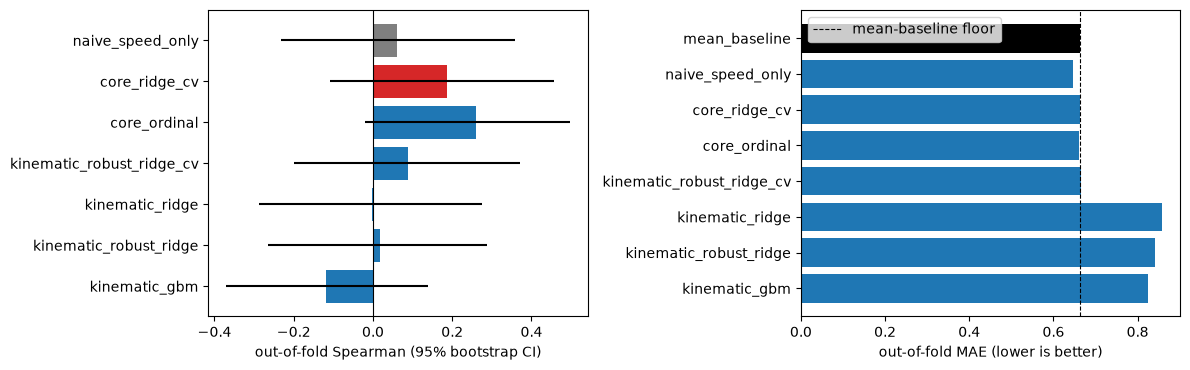

In [6]:
s = summary.set_index("arm").drop("mean_baseline")
lo = s["spearman"] - s["spearman_ci"].map(lambda c: c[0])
hi = s["spearman_ci"].map(lambda c: c[1]) - s["spearman"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
colors = ["tab:red" if a == PRIMARY_ARM else ("tab:gray" if a == BASELINE_ARM else "tab:blue")
          for a in s.index]
ax[0].barh(s.index, s["spearman"], xerr=[lo, hi], color=colors)
ax[0].axvline(0, c="k", lw=.8); ax[0].set_xlabel("out-of-fold Spearman (95% bootstrap CI)")
ax[0].invert_yaxis()
mae = summary.set_index("arm")["mae"]
ax[1].barh(mae.index, mae, color=["k" if a == "mean_baseline" else "tab:blue" for a in mae.index])
ax[1].axvline(mae["mean_baseline"], c="k", ls="--", lw=.8, label="mean-baseline floor")
ax[1].set_xlabel("out-of-fold MAE (lower is better)"); ax[1].invert_yaxis(); ax[1].legend()
plt.tight_layout()

In [7]:
p = summary.set_index("arm").loc[PRIMARY_ARM]
print(f"PRIMARY ({PRIMARY_ARM}) vs {BASELINE_ARM}: "
      f"Δρ = {p['delta_spearman']:+.3f}, 95% CI [{p['delta_ci'][0]:+.3f}, {p['delta_ci'][1]:+.3f}], "
      f"one-sided p = {p['p_vs_naive']:.3f}")
print("Power reminder: n≈47 detects ρ=0.4, n≈30 detects ρ=0.5 (80%, α=.05). "
      "A Δρ of ~0.1–0.2 between two correlated arms needs far more clips.")

PRIMARY (core_ridge_cv) vs naive_speed_only: Δρ = +0.127, 95% CI [-0.088, +0.347], one-sided p = 0.136
Power reminder: n≈47 detects ρ=0.4, n≈30 detects ρ=0.5 (80%, α=.05). A Δρ of ~0.1–0.2 between two correlated arms needs far more clips.


**Reading (single rater).** The fix moves the kinematic models from ρ ≈ 0 (and MAE worse than the
mean) to positive correlations with MAE at the floor; `core_ordinal` is strongest. The primary test is
**directionally consistent with the hypothesis but not significant** at n = 50 with one rater. Do not
re-run model selection on the final consensus — run the *same* table once when the instructors finish.

## 6. Fairness (proposal §7)

`asl-fluency clip-context` derived objective strata for every rated clip, so no human annotation is needed:
* **skin_tone** — Individual Typology Angle (ITA°) from palm pixels located by the landmarks
  (light > 41°, medium 10–41°, dark ≤ 10°; Chardon et al. 1991 bands collapsed to 3).
* **lighting** — mean CIELAB L* of the frame, tertiles of the rated set.

ITA from compressed web video is confounded with white balance/exposure — it is a **proxy stratifier**
(the same pixels the tracker sees), not a demographic label.

In [8]:
ctx = pd.read_csv(resolve_path(cfg, "ratings_dir") / "clip_context.csv", dtype={"clip_id": str})
print(pd.crosstab(ctx["skin_tone"].fillna("undefined"), ctx["lighting"], margins=True), "\n")
print("ITA vs luma Spearman (confound check):",
      round(stats.spearmanr(ctx["ita_deg"], ctx["luma_L"], nan_policy="omit").statistic, 2))

lighting   bright  low  normal  All
skin_tone                          
dark            5    3       4   12
light           3    4       4   11
medium          6    9       8   23
undefined       3    1       0    4
All            17   17      16   50 

ITA vs luma Spearman (confound check): -0.22


**Tracker-quality gap.** §7's bias mechanism is *dropped/jittery tracking* for some groups, which would
corrupt kinematic features independent of skill. Check detection rate per stratum (and whether
ratings themselves differ by stratum, which would confound the stratified metrics).

In [9]:
q = ctx.merge(feats[["clip_id", "detection_rate"]], on="clip_id").merge(
    y.rename("rating"), left_on="clip_id", right_index=True)
rows = []
for f in ("skin_tone", "lighting"):
    g = q.groupby(q[f].fillna("undefined"))
    rows.append(g.agg(n=("clip_id", "size"), detection_rate=("detection_rate", "mean"),
                      mean_rating=("rating", "mean")).assign(factor=f))
    groups = [x["detection_rate"].dropna() for _, x in q.dropna(subset=[f]).groupby(f)]
    print(f"{f}: Kruskal-Wallis on detection_rate p = {stats.kruskal(*groups).pvalue:.3f}")
pd.concat(rows).reset_index(names="stratum").set_index(["factor", "stratum"])

skin_tone: Kruskal-Wallis on detection_rate p = 0.184
lighting: Kruskal-Wallis on detection_rate p = 0.994


n  detection_rate  mean_rating
factor    stratum                                   
skin_tone dark       12           0.984        3.750
          light      11           0.998        4.000
          medium     23           0.996        4.000
          undefined   4           0.977        3.000
lighting  bright     17           0.994        3.529
          low        17           0.991        4.059
          normal     16           0.991        4.000

In [10]:
oof = details[PRIMARY_ARM]["oof"]
marginal_stratified_metrics(y, oof, ctx, ["skin_tone", "lighting"])

,factor,stratum,spearman,pearson,mae,n,mean_signed_error
0,skin_tone,dark,0.068,-0.044,0.688,12.0,0.079
1,skin_tone,light,0.165,0.173,0.679,11.0,-0.151
2,skin_tone,medium,0.172,0.161,0.596,23.0,-0.151
3,skin_tone,NaN,-0.949,-0.874,0.929,4.0,0.808
4,lighting,bright,0.218,0.179,0.664,17.0,0.315
5,lighting,low,0.267,0.279,0.715,17.0,-0.204
6,lighting,normal,-0.096,-0.205,0.607,16.0,-0.178


Strata hold 11–23 clips, so per-stratum correlations have very wide CIs — report them descriptively and
lean on **mean signed error** (systematic over/under-scoring), which is the bias §7 is worried about.

Pilot reading:
* **No tracker-quality gap**: detection rate is ≥ 0.98 in every stratum (Kruskal–Wallis n.s.), so the
  §7 mechanism (dropped frames for some groups) is not visible in the rated set.
* Signed errors are small for skin tone (|bias| ≤ 0.15). The largest is **bright lighting (+0.3)**, but
  that stratum also has the lowest mean rating — a shrunken model over-predicts low-rated clips anywhere,
  so this reads as regression to the mean, not lighting bias. Re-check with the final consensus.
* The `NaN`/undefined ITA rows are clips where palm pixels had b* ≤ 0 (strong colour cast) — itself a
  capture-quality signal; n = 4, so not interpretable on its own. To scale this up cheaply: `asl-fluency clip-context --all --out data/processed/clip_context_all.csv`
gives detection-rate-by-stratum over the whole 7k-clip corpus (no ratings needed).

## 7. Boundary-sensitivity recap (Roadmap Gap 1)

In [11]:
bs = pd.read_csv(resolve_path(cfg, "processed_dir") / "boundary_sensitivity.csv")
bs.assign(in_core=bs["feature"].isin(CORE_FEATURES)).sort_values("min_rho")

,feature,rho_jit2,rho_jit4,rho_jit6,min_rho,in_core
0,letter_dur_std_s,0.136,-0.006,-0.016,-0.016,False
1,letter_dur_cv,0.625,0.481,0.542,0.481,False
2,trans_vel_std,0.912,0.723,0.714,0.714,False
3,trans_vel_mean,0.949,0.754,0.763,0.754,False
4,trans_acc_std,0.938,0.819,0.816,0.816,False
5,trans_jerk_std,0.945,0.843,0.859,0.843,False
6,trans_acc_mean,0.965,0.846,0.848,0.846,False
7,trans_jerk_mean,0.974,0.878,0.893,0.878,False
8,trans_jerk_max,0.972,0.881,0.898,0.881,False
9,letter_dur_mean_s,1.000,0.999,0.998,0.998,False


All three **core** features are whole-clip quantities (rate, LDJ, pause time) and are robust to
boundary jitter, so the primary test does not depend on a better aligner. That justifies deferring the
CTC aligner; the remaining Gap 1 item is human: `asl-fluency label-boundaries` on these same 50 clips to
report actual boundary error in the paper.

## 8. Dress rehearsal on simulated raters (plumbing only)

The 3-rater path (agreement → consensus → evaluate) has never run on real data. Simulate two extra raters
as `fluent_c` + noise to make sure it works end-to-end **today**. These numbers are meaningless as results
and are never written to disk.

In [12]:
rng = np.random.default_rng(0)
base = ratings[ratings["rater_id"] == "fluent_c"][["clip_id", "rating"]]
sims = [base.assign(rater_id=f"sim_{k}",
                    rating=np.clip(np.rint(base["rating"] + rng.normal(0, sd, len(base))), 1, 5))
        for k, sd in (("a", 0.6), ("b", 0.9))]
sim = pd.concat([base.assign(rater_id="fluent_c"), *sims], ignore_index=True)
print({k: round(v, 3) for k, v in agreement_report(sim).items()})
y_sim = consensus_scores(sim)
sim_summary, _ = run_ablation(feats, y_sim, group_col="signer_id", n_splits=5, bootstrap_iters=200)
sim_summary[["arm", "spearman", "mae", "delta_spearman", "p_vs_naive"]]

{'n_clips': 50.0, 'n_raters': 3.0, 'fleiss_kappa': 0.226, 'icc_2k': 0.591}


,arm,spearman,mae,delta_spearman,p_vs_naive
0,mean_baseline,NaN,0.668,NaN,NaN
1,naive_speed_only,0.069,0.646,0.000,NaN
2,core_ridge_cv,0.317,0.622,0.248,0.005
3,core_ordinal,0.346,0.617,0.276,0.020
4,kinematic_robust_ridge_cv,0.306,0.628,0.236,0.035
5,kinematic_ridge,0.241,0.715,0.172,0.200
6,kinematic_robust_ridge,0.255,0.699,0.185,0.170
7,kinematic_gbm,0.170,0.671,0.100,0.290


## 9. When the instructor ratings arrive

```bash
asl-fluency agreement data/ratings/ratings_intake.csv            # 1. ICC(2,k) >= 0.6 ?
asl-fluency evaluate  data/ratings/ratings_intake.csv            # 2. the pre-registered table, ONCE
asl-fluency evaluate  data/ratings/ratings_intake.csv --rater instructor_a   # per-rater (if ICC low)
asl-fluency train                                                # 3. primary arm (config default)
asl-fluency score --from-features                                # 4. score the corpus
```
Then re-execute this notebook top to bottom (it reads whatever is in `ratings_intake.csv`). If the
CIs are too wide **and** time allows: `asl-fluency rating-sheet … --batch 2`.

Deadline fallback: if instructors miss the cutoff, the single-rater pilot above *is* the result — report
it as such, with agreement listed as future work.

## 10. Notes & limitations (for the paper)

* **One rater so far.** Every number above reflects one person's judgement; no reliability estimate yet.
* **Restricted range.** Corpus is mostly fluent signers → ratings cluster at 3–5, capping correlations.
* **Small n.** 50 clips / 27 signers; signer-disjoint 5-fold CV ⇒ ~40 training clips per fold. This is why
  the model is 3 a-priori features with shrinkage, not 18 features or a deep model (§7).
* **Uniform segmentation.** Core features are whole-clip and boundary-robust; `trans_*` features are not
  in the primary arm.
* **Fairness proxy.** ITA on web video ≠ skin tone; it's confounded with capture conditions. Strata are small.
* **Frame rate.** Frame directories have no native fps; 30 fps assumed for all rate features.